# The credit corpus: what was delivered

Start with the unit of generalization: a dataset, not an individual row. This inventory explains the scale, imbalance and provenance of the 17 PD and 8 LGD tables before interpreting adaptation effects.

The corpus defines the population to which the CPT study applies; related source populations and local preprocessing limit broader generalization.


## 0. Evidence and scope

The availability tables distinguish observed measurements from unavailable outcomes. Missing measurements are not zero effects.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, publication as pub, diagnostics as dg
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
from src.data.dataset_names import display_frame
style.apply()
sink = FigureSaver('general/01_raw_data')
report = cp.NotebookReport('The credit corpus: what was delivered', sink=sink)
from src.visualize import corpus as cv
print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'The corpus defines the population to which the CPT study applies; related source populations and local preprocessing limit broader generalization.')

DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Availability and inventory

Registered inputs and observed files are distinguished. Private tables retain anonymized names.

In [2]:
raw = cv.raw_inventory()
report.table('Delivered tables', raw[['track','dataset_id','rows','features','file_mb','target_in_raw']])
report.add('1. Availability and inventory', cv.inventory_summary(raw, 'Raw'))


,track,dataset_id,rows,features,file_mb,target_in_raw
0,pd,GMSC,150000,10,6.32,True
1,pd,Taiwan Credit Card,30000,24,2.73,True
2,pd,Vehicle Loan,233154,40,39.89,True
3,pd,LendingClub,9578,13,0.72,True
4,pd,Myhom,7000,9,0.27,True
5,pd,Hackerearth,532428,44,137.47,True
6,pd,Cobranded,80000,48,16.55,True
7,pd,German Credit,999,20,0.08,False
8,pd,PropPD1,100514,18,17.94,True
9,pd,Thomas,1225,14,0.08,True


## 2. Corpus geometry

Row count and predictor count can differ by orders of magnitude. Log axes show that geometry without letting one large table hide the others.

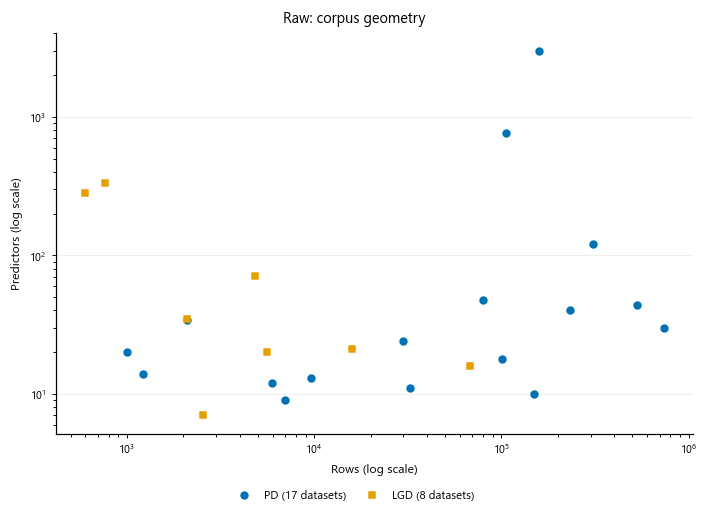

Predictor count versus row count in the raw corpus, on logarithmic axes. Each point is one available dataset; color and marker distinguish PD and LGD on common axes. Raw columns exclude the registered target or the recognized final label column in German Credit, but can include identifiers later removed during cleaning.

In [3]:
cp.show(sink, cv.plot_geometry(raw, 'Raw'))
report.add('2. Corpus geometry', 'Each point represents one available dataset.')


## 3. Dataset sizes and missingness

Dataset details are split into balanced pages when needed for legibility. Missingness in delivered columns is not the same as missingness among final predictors.

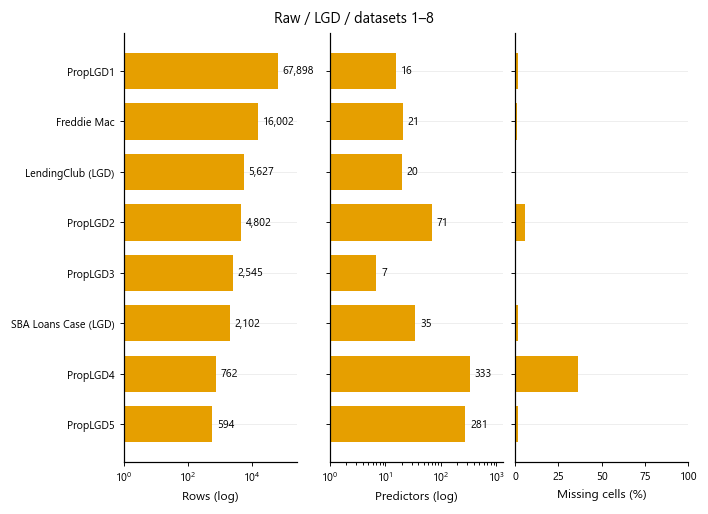

Row counts, predictor counts and missing-cell percentages for 8 LGD datasets, sorted by decreasing size and continued across pages. Raw missingness uses all delivered columns, including a target column when present. Counts use logarithmic axes with a baseline of one; labels give exact counts and bar lengths must not be read as linear ratios. Missingness uses a zero-based linear axis. Missing files remain unknown.

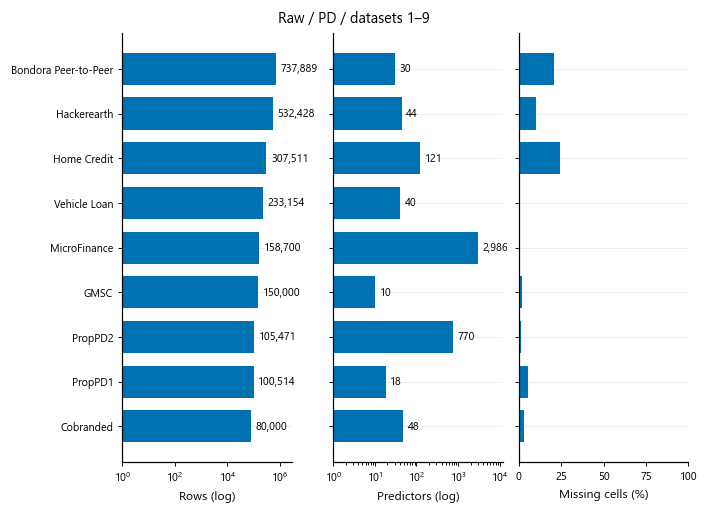

Row counts, predictor counts and missing-cell percentages for 9 PD datasets, sorted by decreasing size and continued across pages. Raw missingness uses all delivered columns, including a target column when present. Counts use logarithmic axes with a baseline of one; labels give exact counts and bar lengths must not be read as linear ratios. Missingness uses a zero-based linear axis. Missing files remain unknown.

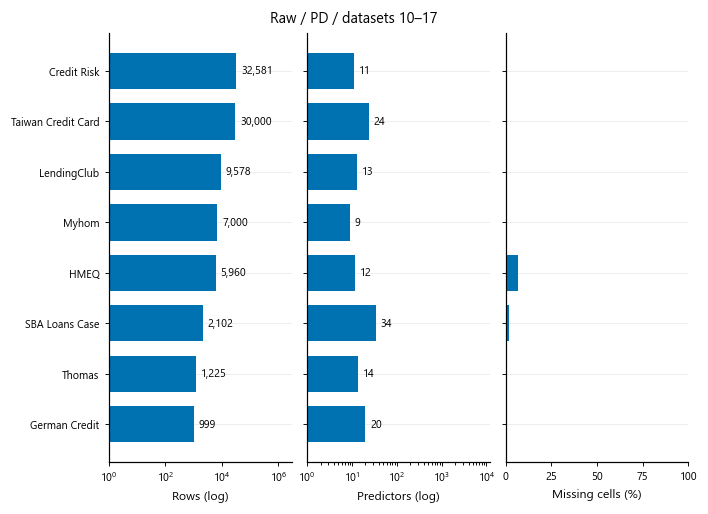

Row counts, predictor counts and missing-cell percentages for 8 PD datasets, sorted by decreasing size and continued across pages. Raw missingness uses all delivered columns, including a target column when present. Counts use logarithmic axes with a baseline of one; labels give exact counts and bar lengths must not be read as linear ratios. Missingness uses a zero-based linear axis. Missing files remain unknown.

In [4]:
cp.show(sink, cv.plot_profiles(raw, 'Raw'))
report.add('3. Dataset sizes and missingness', 'Raw missingness includes every delivered column.')


## 4. Concentration of rows

Equal table visitation is a consequential design choice when a small number of tables contain most rows.

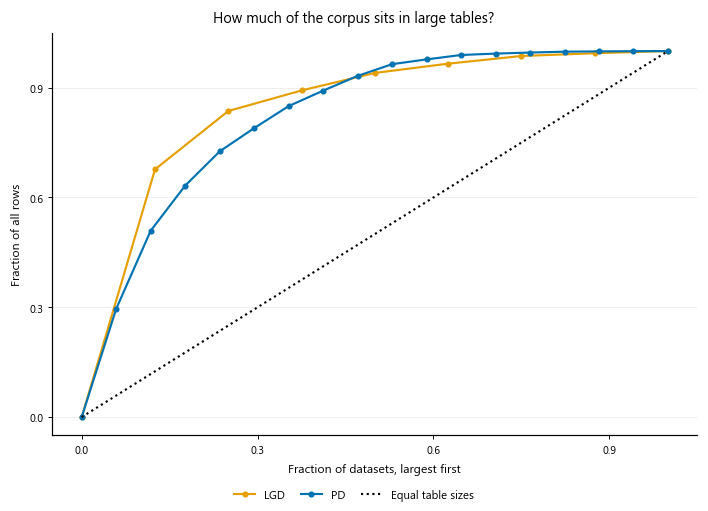

Cumulative fraction of corpus rows contributed by datasets ordered from largest to smallest, separately for PD and LGD. The diagonal represents equal table sizes. This summarizes row imbalance; it does not by itself give model-specific batch or optimizer-update counts.

In [5]:
cp.show(sink, cv.plot_concentration(raw))
report.add('4. Concentration of rows', 'Corpus row shares do not directly determine optimizer-update shares.')


## 5. Source coverage

Dataset counts describe the provenance of the corpus; related sources are not automatically independent evidence.

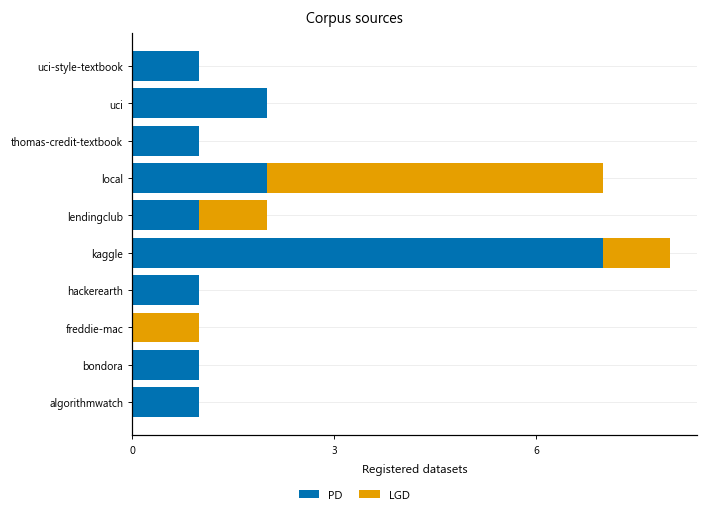

Registered dataset counts by source and task. Dataset counts describe provenance, not statistical independence between related sources.

In [6]:
cp.show(sink, cv.plot_sources(raw))
report.add('5. Source coverage', 'Sources are summarized within each task.')


## 6. Delivery checks

A target can be renamed or derived during preprocessing. The checks below distinguish those expected transformations from missing deliveries and verify the processed target column.

In [7]:
flags = cv.delivery_checks(raw)
report.table('Target construction and delivery checks', flags)
report.add('6. Delivery checks', 'No delivery discrepancies.' if flags.empty else 'Expected preprocessing is distinguished from missing inputs; the processed target check confirms column presence, not the absence of every possible data issue.')


,track,dataset,target_in_raw,target_in_processed,status,explanation
0,pd,German Credit,False,True,Expected preprocessing,The final raw column is the label; preprocessi...
1,lgd,SBA Loans Case (LGD),False,True,Expected preprocessing,Preprocessing selects defaulted loans and deri...


## Complete text summary

Complete numerical values and figure captions, following the section order above.

In [8]:
print(report.summary(sink))


The credit corpus: what was delivered

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
The corpus defines the population to which the CPT study applies; related source populations and local preprocessing limit broader generalization.

1. Availability and inventory
Raw: 25/25 registered datasets available.
       datasets     rows  min_rows  max_rows  max_features
track                                                     
lgd           8   100332       594     67898           333
pd           17  2495112       999    737889          2986

Table: Delivered tables
CSV (first column: row index)
row,track,dataset_id,rows,features,file_mb,target_in_raw
0,pd,GMSC,150000,10,6.32,True
1,pd,Taiwan Credit Card,30000,24,2.73,True
2,pd,Vehicle Loan,233154,40,39.89,True
3,pd,LendingClub,9578,13,0.72,True
4,pd,Myhom,7000,9,0.27,True
5,pd,Hackerearth,532428,44,137.47,Tr